# 39 · seed 21

- Same as 39_resizemix50_seed42.ipynb; only SEED = 21 and SAVE_DIR changed.


In [1]:
import random
from pathlib import Path
import torch

# torch.set_num_threads(8)
# print("PyTorch CPU threads:", torch.get_num_threads())

from torch import nn
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.transforms import InterpolationMode

from src.dataset.balanced_class_subset import BalancedClassSubset
from src.dataset.tiny_imagenet_dataset import TinyImageNetLoader, get_selected_classes, get_selected_class_names
from src.utils.utils import means, stds, convert_to_rgb, get_device, print_device_info, set_seed, make_generator, count_parameters
from src.utils.plot_graph import show_image, show_mix_samples, plot_training_curves
from src.dataset.resizemix import ResizeMixDataset
from src.model.cnn import StandardCNN
from src.utils.metrics_csv import print_metrics
from src.utils.train_model import TrainModel
from src.utils.checkpoint import CheckpointManager

RESUME = False
SEED = 21
NUM_CLASSES = 200
TRAIN_PER_CLASS = 500
VAL_PER_CLASS = 50
BATCH_SIZE = 64
NUM_WORKERS = 4
EPOCHS = 100
INITIAL_LR = 0.05
MIN_LR = 1e-05
WEIGHT_DECAY = 0.0001
LABEL_SMOOTHING = 0.1
CLASSIFIER_DROPOUT = 0.35
CLEAN_EVAL_INTERVAL = 5

RESIZEMIX_SCALE = (0.1, 0.8)
RESIZEMIX_PROB = 0.50

TINY_ROOT = Path('../../data/tiny_imagenet/tiny-imagenet-200')
SAVE_DIR = Path('../../checkpoints/cnn/39_resizemix50_seed21')
SAVE_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = get_device()

set_seed(SEED)

print('Device:', DEVICE)
print('Dataset root:', TINY_ROOT)
print('DataLoader workers:', NUM_WORKERS)
print('Epochs:', EPOCHS)
print(f'ResizeMix on {RESIZEMIX_PROB:.0%} of images | scale={RESIZEMIX_SCALE} | RandAugment after mixing')

Device: mps
DataLoader workers: 4
Epochs: 100
ResizeMix on 50% of images | scale=(0.1, 0.8) | RandAugment after mixing


In [2]:
print_device_info(DEVICE)

Number of MPS devices: 1


## 1. Dataset and transforms

In [4]:
before_mix_tf = transforms.Compose(
    [transforms.Lambda(convert_to_rgb), transforms.RandomCrop(64, padding=4, padding_mode='reflect'),
     transforms.RandomHorizontalFlip(p=0.5)])
after_mix_tf = transforms.Compose(
    [transforms.RandAugment(num_ops=2, magnitude=5, interpolation=InterpolationMode.BILINEAR), transforms.ToTensor(),
     transforms.Normalize(mean=means, std=stds)])
test_tf = transforms.Compose(
    [transforms.Lambda(convert_to_rgb), transforms.ToTensor(), transforms.Normalize(mean=means, std=stds)])

train_dataset, val_dataset, _, _ = TinyImageNetLoader(seed=SEED, root=TINY_ROOT, train_transform=before_mix_tf,
                                                      test_transform=test_tf).load()
clean_train_dataset, _, _, _ = TinyImageNetLoader(seed=SEED, root=TINY_ROOT, train_transform=test_tf,
                                                  test_transform=test_tf).load()

if not hasattr(clean_train_dataset, 'transform'):
    raise AttributeError('Expected the dataset to expose a transform attribute.')

train_subset = BalancedClassSubset(train_dataset, get_selected_classes(NUM_CLASSES), TRAIN_PER_CLASS, seed=SEED)
clean_train_subset = BalancedClassSubset(clean_train_dataset, get_selected_classes(NUM_CLASSES), TRAIN_PER_CLASS, seed=SEED)
val_subset = BalancedClassSubset(val_dataset, get_selected_classes(NUM_CLASSES), VAL_PER_CLASS, seed=SEED + 1)

assert train_subset.samples == clean_train_subset.samples, 'Clean and augmented training subsets differ.'
assert len(train_subset) == NUM_CLASSES * TRAIN_PER_CLASS
assert len(val_subset) == NUM_CLASSES * VAL_PER_CLASS

CLASS_NAMES = get_selected_class_names(train_dataset, TINY_ROOT, NUM_CLASSES)

print('Train:', len(train_subset), 'Validation:', len(val_subset))

Train: 100000 Validation: 10000


## 2. DataLoaders (macOS / Jupyter safe)

In [5]:
loader_generator = make_generator(SEED)

loader_options = {'batch_size': BATCH_SIZE, 'num_workers': NUM_WORKERS, 'pin_memory': DEVICE.type == 'cuda',
                  'persistent_workers': NUM_WORKERS > 0, **({'prefetch_factor': 2} if NUM_WORKERS > 0 else {})}

train_mix_dataset = ResizeMixDataset(train_subset, after_mix_tf, scale=RESIZEMIX_SCALE, mix_prob=RESIZEMIX_PROB)
train_loader = DataLoader(train_mix_dataset, shuffle=True, generator=loader_generator, **loader_options)
val_loader = DataLoader(val_subset, shuffle=False, **loader_options)
clean_train_loader = DataLoader(clean_train_subset, shuffle=False, **loader_options)

print('Training batches:', len(train_loader))
print('Validation batches:', len(val_loader))

Training batches: 1563
Validation batches: 157


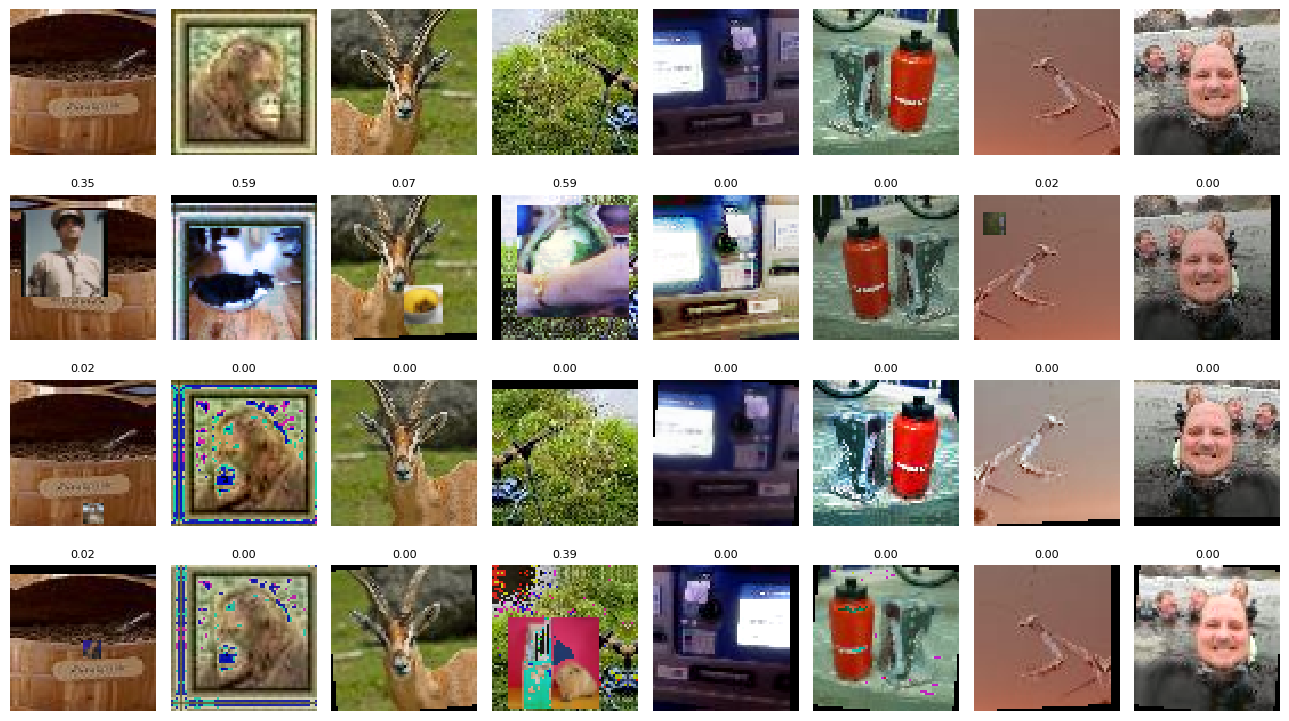

In [6]:
# Sample check: plain images (top) and training images with ResizeMix
show_mix_samples(train_dataset, train_subset, train_mix_dataset)

## Visual Check

In [7]:
# NUM_SHOW = 5
#
# train_iter = iter(train_loader)
# clean_train_iter = iter(clean_train_loader)
# val_iter = iter(val_loader)

In [8]:
# train_images, train_labels = next(train_iter)
# clean_train_images, clean_train_labels = next(clean_train_iter)
# val_images, val_labels_batch = next(val_iter)
#
# show_image(train_images, train_labels, NUM_SHOW, CLASS_NAMES, name="Train Images", has_norm=True)
# show_image(clean_train_images, clean_train_labels, NUM_SHOW, CLASS_NAMES, name="Clean Train Images", has_norm=True)
# show_image(val_images, val_labels_batch, NUM_SHOW, CLASS_NAMES, name="Validation Images", has_norm=True)

## 3. Model, optimizer and cosine scheduler

In [9]:
# Model class: src/model/cnn.py (StandardCNN)

# ==========================================
# MODEL INITIALIZATION
# ==========================================

base_model = StandardCNN(num_classes=NUM_CLASSES, block3_dropout=0.15, block4_dropout=0.25, classifier_dropout=0.35,
                         level4_dilation=2)

total_params = count_parameters(base_model)
print(f"Parameters: {total_params:,} ({total_params / 1e6:.3f}M)")
print("Architecture: 8 conv (2+2+2+2, conv8 dilation 2) | BatchNorm x9 (8 conv + dense) | LeakyReLU 0.05 | MaxPool x3 | Dropout2d 0.15, 0.25 | GAP 512 → dense 512 (dropout 0.35) → 200")

model = base_model.to(DEVICE)



# LOSS, OPTIMIZER & SCHEDULER
criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
optimizer = torch.optim.SGD(model.parameters(), lr=INITIAL_LR, momentum=0.9, weight_decay=WEIGHT_DECAY, nesterov=True)

TOTAL_STEPS = EPOCHS * len(train_loader)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=TOTAL_STEPS, eta_min=MIN_LR)

# SANITY CHECK
model.eval()
with torch.no_grad():
    dummy = torch.randn(2, 3, 64, 64, device=DEVICE)
    logits, features = model(dummy, return_features=True)

print("Logits shape:", logits.shape)
print("Feature shape:", features.shape)
model.train()

Parameters: 2,710,376 (2.710M)
Architecture: 8Conv (2+2+2+2) | MaxPool x3 | BatchNorm x8 | LeakyReLU 0.05 | GAP → 512 → 512 → 200
Logits shape: torch.Size([2, 200])
Feature shape: torch.Size([2, 512])


Our08CNNPoolBN_V2(
  (level1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): LeakyReLU(negative_slope=0.05, inplace=True)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): LeakyReLU(negative_slope=0.05, inplace=True)
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (level2): Sequential(
    (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): LeakyReLU(negative_slope=0.05, inplace=True)
    (3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (4): BatchNorm2d(128, eps=1e-05

## 4. Checkpoints and resume

In [10]:
# Checkpoints and resume (src/utils/checkpoint.py); RESUME needs the same config
CONFIG = dict(num_classes=NUM_CLASSES, batch_size=BATCH_SIZE, epochs=EPOCHS, train_per_class=TRAIN_PER_CLASS,
              val_per_class=VAL_PER_CLASS, classifier='8conv_v2_gap_dense_fc', classifier_dropout=CLASSIFIER_DROPOUT,
              augmentation='resizemix_half_of_images_randaugment2m5_after', resizemix_scale=RESIZEMIX_SCALE,
              resizemix_prob=RESIZEMIX_PROB)

ckpt = CheckpointManager(SAVE_DIR, model, optimizer, scheduler, CONFIG, DEVICE, generators={'loader': loader_generator})
history, best_acc, best_epoch, start_epoch = ckpt.start(RESUME)
BEST_PATH = ckpt.best_path

Starting fresh 8Conv V2 + GAP + Dense + ResizeMix on half of images training from epoch 1.


## 5. Training and validation

In [12]:
# Training with backprop (src/utils/train_model.py); writes metrics.csv
trainer = TrainModel(model, optimizer, scheduler, criterion, DEVICE)
best_acc, best_epoch = trainer.fit(train_loader, val_loader, clean_train_loader, EPOCHS, history, SAVE_DIR,
                                   ckpt.save_latest, start_epoch=start_epoch, best_acc=best_acc, best_epoch=best_epoch,
                                   clean_eval_interval=CLEAN_EVAL_INTERVAL,
                                   best_info={'class_names': CLASS_NAMES,
                                              'experiment': 'Our 08 V2: max-pool after levels 1, 2, 3, Dropout2d, BatchNorm, GAP + dense 512 head, archive flow, ResizeMix on half of images, RandAugment after mixing'})

  0%|          | 0/100 [00:00<?, ?it/s]

Train:   0%|          | 0/1563 [00:06<?, ?it/s]

Eval:   0%|          | 0/1563 [00:07<?, ?it/s]

Eval:   0%|          | 0/157 [00:05<?, ?it/s]

Epoch 001/100 | Train: 5.19% / 4.8424 | Val: 10.07% / 4.4220 | Clean Train: 10.72% / 4.4036 | LR: 0.0499877 | Best: 10.07% (epoch 1)


Train:   0%|          | 0/1563 [00:00<?, ?it/s]

... (312 outputs left out)

Train:   0%|          | 0/1563 [00:00<?, ?it/s]

Eval:   0%|          | 0/1563 [00:00<?, ?it/s]

Eval:   0%|          | 0/157 [00:00<?, ?it/s]

Epoch 100/100 | Train: 56.07% / 2.6396 | Val: 63.43% / 2.1974 | Clean Train: 83.37% / 1.5628 | LR: 0.0000100 | Best: 63.62% (epoch 96)
Training finished at epoch 100. Best validation accuracy: 63.62% (epoch 96)


In [ ]:
# All metrics per epoch (from metrics.csv), then best and mean val of the last 5 epochs
print_metrics(SAVE_DIR / 'metrics.csv')

## 6. Training and validation curves

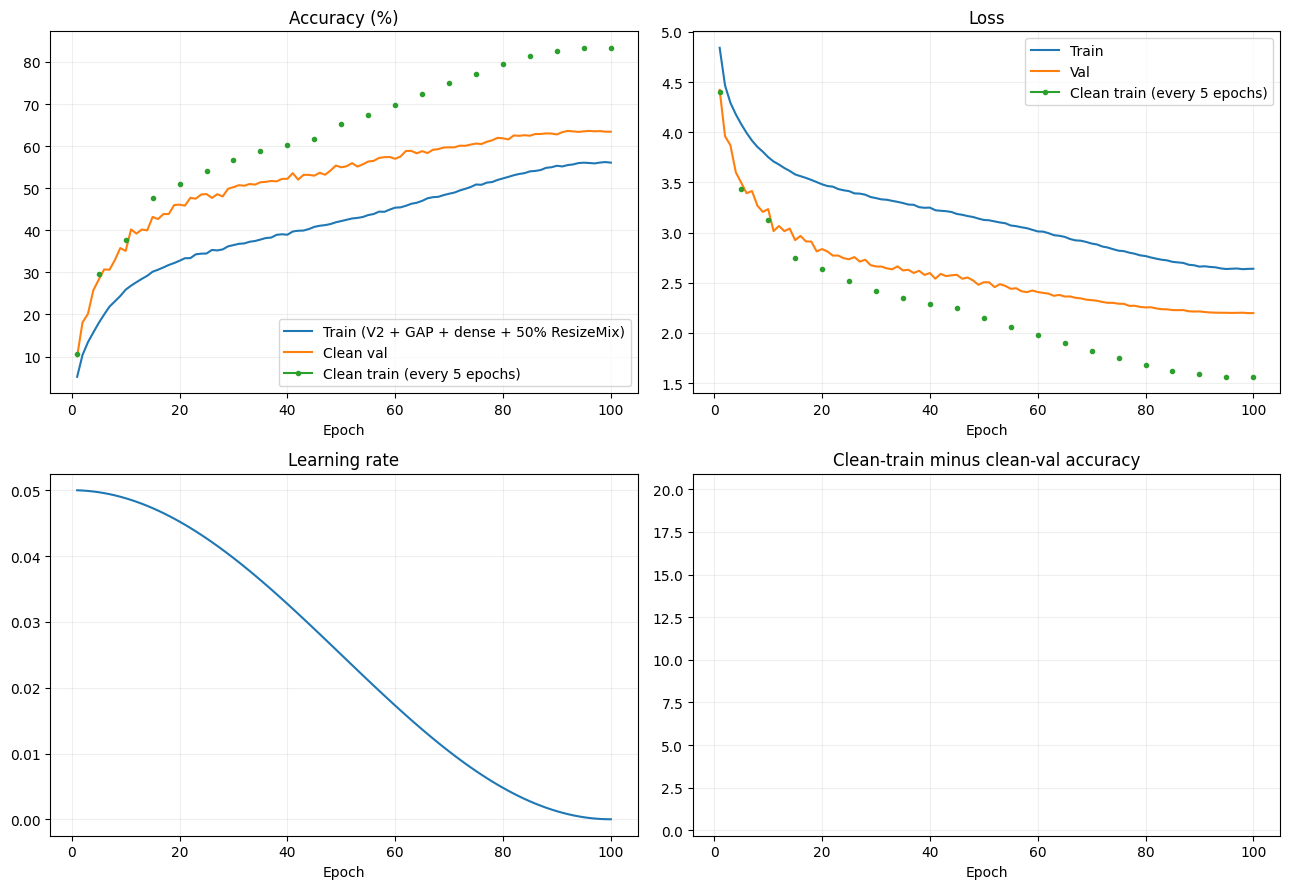

Eval:   0%|          | 0/1563 [00:00<?, ?it/s]

Eval:   0%|          | 0/157 [00:00<?, ?it/s]

Best checkpoint: clean train 83.33%, clean val 63.62%, gap 19.71 pp


In [13]:
plot_training_curves(history, train_label='Train (BP, 50% ResizeMix)')

best = ckpt.load_best()
model.eval()

clean_train_loss, clean_train_acc = trainer.run_epoch(clean_train_loader)
clean_val_loss, clean_val_acc = trainer.run_epoch(val_loader)

print(
    f'Best checkpoint: clean train {clean_train_acc:.2f}%, clean val {clean_val_acc:.2f}%, gap {clean_train_acc - clean_val_acc:.2f} pp')